In [1]:
import sys

sys.path.append("..")
import numpy as np
import torch.nn as nn
import torch
import torch.nn.functional as F
from data.utils.r_peak_processing import detect_r_peaks
import pandas as pd
from interpretability_methods.ig import run_ig
from interpretability_methods.lime import run_lime
import os

In [2]:
differences = np.load("han_updated_v_original_sinus_arrhythmia.npy", allow_pickle=True)

In [3]:
ORIG_PATH = os.path.join("model_pths", "han_original.pth")
UPD_PATH  = os.path.join("model_pths", "han_updated.pt")
DATA_PATH = os.path.join("C.npy")

In [4]:
FS = 500
PRE_SAMPLES  = 99
POST_SAMPLES = 201

class ChannelAttention(nn.Module):
    def __init__(self, channels, ratio=8):
        super().__init__()
        mid = max(1, channels // ratio)
        self.mlp = nn.Sequential(
            nn.Linear(channels, mid, bias=True),
            nn.ReLU(),
            nn.Linear(mid, channels, bias=True),
        )

    def forward(self, x):
        avg_out = self.mlp(torch.mean(x, dim=2))
        max_out = self.mlp(torch.max(x, dim=2).values)
        return x * torch.sigmoid(avg_out + max_out).unsqueeze(2)


class SegmentAttention(nn.Module):
    def __init__(self, input_dim, units):
        super().__init__()
        self.linear = nn.Linear(input_dim, units, bias=True)
        self.u = nn.Parameter(torch.randn(units))

    def forward(self, inputs):
        v = torch.tanh(self.linear(inputs))
        alphas = F.softmax(torch.matmul(v, self.u), dim=1)
        return torch.sum(inputs * alphas.unsqueeze(-1), dim=1), alphas

class TimeDistributedSegmentAttention(nn.Module):
    def __init__(self, input_dim, units):
        super().__init__()
        self.segment_attention = SegmentAttention(input_dim, units)

    def forward(self, inputs):
        B, S, T, D = inputs.shape
        out, alphas = self.segment_attention(inputs.view(B * S, T, D))
        return out.view(B, S, D), alphas.view(B, S, T)


class HANOriginal(nn.Module):
    def __init__(self, num_classes=11, conv_channels=128, segment_hidden=128,
                 sequence_hidden=512, fc_hidden=512, dropout=0.4):
        super().__init__()
        self.conv1d = nn.Conv1d(12, conv_channels, kernel_size=25, padding=12)
        self.channel_attention = ChannelAttention(conv_channels, ratio=8)
        self.pool = nn.MaxPool1d(kernel_size=3, stride=2, padding=1)
        self.lstm_segment = nn.LSTM(conv_channels, segment_hidden, batch_first=True)
        self.time_distributed_attention = TimeDistributedSegmentAttention(
            segment_hidden, segment_hidden
        )
        self.lstm_sequence = nn.LSTM(segment_hidden, sequence_hidden, batch_first=True)
        self.final_attention = SegmentAttention(sequence_hidden, sequence_hidden)
        self.fc = nn.Linear(sequence_hidden, fc_hidden)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(fc_hidden, num_classes)

    def forward(self, x):
        # x: (B, S, T, C)
        B, S, T, C = x.shape
        x = x.view(B * S, T, C).permute(0, 2, 1)
        x = self.pool(self.channel_attention(self.conv1d(x))).permute(0, 2, 1)
        seg_out, _ = self.lstm_segment(x)
        seg_out = seg_out.view(B, S, seg_out.shape[1], seg_out.shape[2])
        seg_feats, _ = self.time_distributed_attention(seg_out)
        seq_out, _ = self.lstm_sequence(seg_feats)
        final_vec, _ = self.final_attention(seq_out)
        return self.classifier(self.dropout(F.relu(self.fc(final_vec))))


class HANUpdated(nn.Module):
    def __init__(self, num_classes=11, conv_channels=128, segment_hidden=128,
                 sequence_hidden=512, fc_hidden=512, dropout=0.4):
        super().__init__()
        self.conv1d = nn.Conv1d(12, conv_channels, kernel_size=25, padding=12)
        self.channel_attention = ChannelAttention(conv_channels, ratio=8)
        self.pool = nn.MaxPool1d(kernel_size=3, stride=2, padding=1)
        self.lstm_segment = nn.LSTM(conv_channels, segment_hidden, batch_first=True)
        self.time_distributed_attention = TimeDistributedSegmentAttention(
            segment_hidden, segment_hidden
        )
        self.lstm_sequence = nn.LSTM(segment_hidden + 1, sequence_hidden, batch_first=True)
        self.final_attention = SegmentAttention(sequence_hidden, sequence_hidden)
        self.fc = nn.Linear(sequence_hidden, fc_hidden)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(fc_hidden, num_classes)

    def forward(self, x, rr_intervals):
        # x: (B, S, T, C) | rr_intervals: (B, S)
        B, S, T, C = x.shape
        x = x.view(B * S, T, C).permute(0, 2, 1)
        x = self.pool(self.channel_attention(self.conv1d(x))).permute(0, 2, 1)
        seg_out, _ = self.lstm_segment(x)
        seg_out = seg_out.view(B, S, seg_out.shape[1], seg_out.shape[2])
        seg_feats, _ = self.time_distributed_attention(seg_out)
        combined = torch.cat([seg_feats, rr_intervals.unsqueeze(-1)], dim=-1)
        seq_out, _ = self.lstm_sequence(combined)
        final_vec, _ = self.final_attention(seq_out)
        return self.classifier(self.dropout(F.relu(self.fc(final_vec))))


def compute_rr(sample):
    ecg = sample["ecg"]                          # (12, 5000)
    r_peaks = detect_r_peaks(ecg, FS)
    if len(r_peaks) == 0:
        return None

    valid_mask = (r_peaks - PRE_SAMPLES >= 0) & (r_peaks + POST_SAMPLES <= ecg.shape[1])
    valid_peaks = r_peaks[valid_mask]
    if len(valid_peaks) < 2:
        return None

    rr = np.diff(valid_peaks) / FS
    rr = np.insert(rr, 0, np.mean(rr)).astype(np.float32)   # (n_beats,)

    stored_n_beats = sample["beats"].shape[0]
    if stored_n_beats != rr.shape[0]:
        return None

    return rr

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
metadata = pd.read_csv("metadata.csv")
print(f"Device: {device}")

Device: cuda


In [6]:
print("Loading models...")
han_orig = HANOriginal().to(device)
han_orig.load_state_dict(torch.load(ORIG_PATH, map_location=device))
han_orig.eval()

han_upd = HANUpdated().to(device)
han_upd.load_state_dict(torch.load(UPD_PATH, map_location=device))
han_upd.eval()
print("Models loaded.")

samples = np.load(DATA_PATH, allow_pickle=True)
print(f"Loaded {len(samples)} sinus arrhythmia samples from C.npy")

Loading models...
Models loaded.
Loaded 2575 sinus arrhythmia samples from C.npy


In [7]:
differences[0]

{'ecg_id': 'A00074',
 'full_ecg': array([[-0.05136874, -0.05148904, -0.05235035, ..., -0.06662011,
         -0.06887665, -0.07145157],
        [-0.02973761, -0.02919888, -0.02742488, ..., -0.07347753,
         -0.07270546, -0.07208455],
        [ 0.01912824,  0.01963642,  0.02269478, ..., -0.00666416,
         -0.00391849, -0.00131614],
        ...,
        [-0.05989832, -0.06058883, -0.06450069, ..., -0.1348181 ,
         -0.13684258, -0.13752384],
        [-0.03742198, -0.03820494, -0.04229838, ..., -0.12637761,
         -0.13038442, -0.13412485],
        [-0.03442398, -0.03490715, -0.03727319, ..., -0.09301769,
         -0.09725516, -0.10160268]], dtype=float32),
 'orig_pred': 0,
 'upd_pred': 1,
 'orig_logits': array([ 2.7817345,  2.3618312, -3.09017  , -8.340747 , -5.7647586,
        -3.7780745, -3.7912123, -5.397254 , -3.5042958, -3.3067434,
        -3.8757656], dtype=float32),
 'upd_logits': array([-0.51032424,  7.3193717 , -4.499457  , -3.1339793 , -6.43884   ,
        -2.748477

In [8]:
metadata[metadata['ECG_ID'] == "A00001"]

,ECG_ID,AHA_Code,Patient_ID,Age,Sex,N,Date
0,A00001,22;23,S00001,55,M,5000,2020-03-04


      ECG_ID AHA_Code Patient_ID  Age Sex     N        Date
3157  A03158       22     S03128   57   M  5000  2019-10-20
Computing Integrated Gradients attributions...


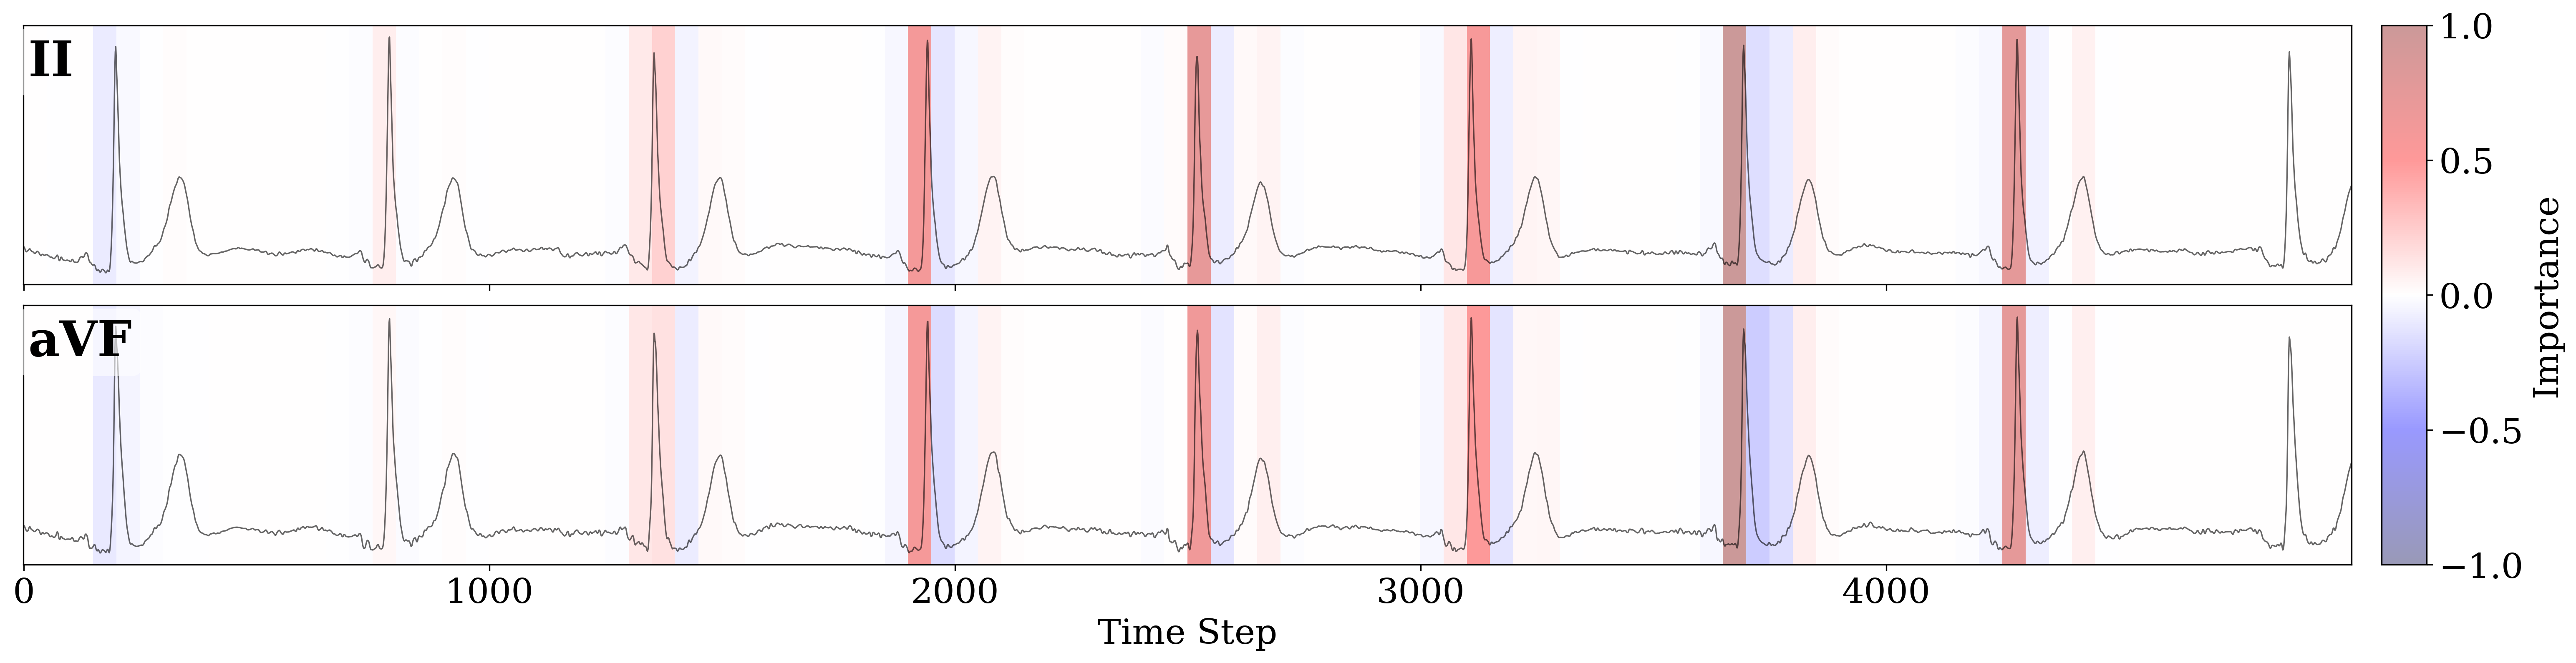

Attribution Range (Lead II): -0.1613 to 1.0000
Mean Abs Attribution (Lead II): 0.0572
Number of windows: 100
Window size: 50 samples
RR mode: neutral_mean
Actual label 1 - . Predicted 1
Computing Integrated Gradients attributions...


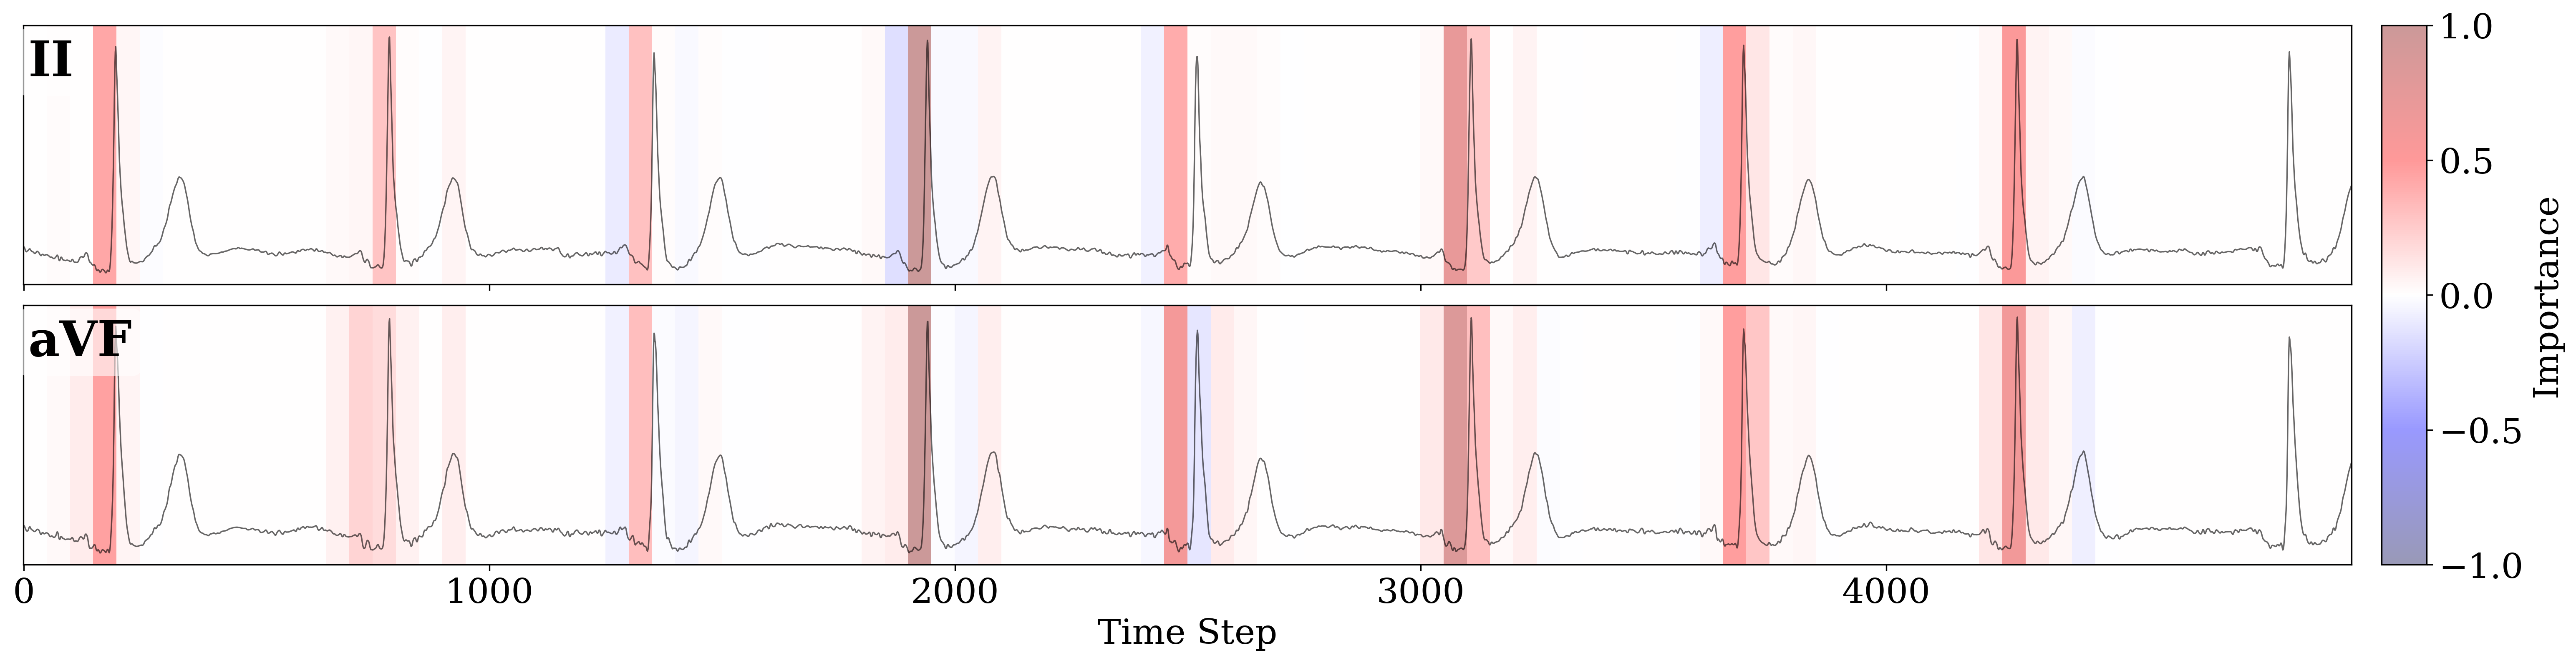

Attribution Range (Lead II): -0.1506 to 1.0000
Mean Abs Attribution (Lead II): 0.0571
Number of windows: 100
Window size: 50 samples
RR mode: n/a
Actual label 1 - . Predicted 0
--------------------------------


In [25]:
for sample in differences[100:500]:
    # print(sample['ecg_id'])
    # if metadata[metadata['ECG_ID'] == sample['ecg_id']]['AHA_Code'].item() != '22':
    if metadata[metadata['ECG_ID'] == sample['ecg_id']]['ECG_ID'].item() != 'A03158':
        continue

    print(metadata[metadata['ECG_ID'] == sample['ecg_id']])
    x  = torch.from_numpy(np.asarray(sample['beats'].cpu())).float().to(device)
    rr = sample['rr_tensor'].float().to(device)

    full_ecg = torch.tensor(sample['full_ecg'], dtype=torch.float32, device=device)[:, :5000].unsqueeze(0)
    r_peaks  = detect_r_peaks(full_ecg[0].cpu().numpy(), fs=500)

    true_r_peaks = [
        p for p in r_peaks
        if max(0, p - PRE_SAMPLES) - min(5000, p + POST_SAMPLES) + (PRE_SAMPLES + POST_SAMPLES) == 0
    ]

    run_ig(han_upd, x, "", 1, rr=rr, baseline='zero', full=full_ecg,
       r_peaks=true_r_peaks, pre_samples=99, post_samples=201, window_size=50, leads=[1, 5], rr_mode="neutral_mean")
    
    run_ig(han_orig, x, "", 1, baseline='zero', full=full_ecg,
       r_peaks=true_r_peaks, pre_samples=99, post_samples=201, window_size=50, leads=[1, 5])
    
    print("--------------------------------")
